# Idiomatic versus literal MWE usage

Auxiliary task added after proposal feedback. Labels are not sarcasm annotations. See ../docs/FIGURATIVE_EXPANSION.md for sources, terms and interpretation.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root = Path.cwd().resolve()
while not (root / 'src' / 'preprocess.py').exists():
    if root == root.parent:
        raise RuntimeError('Open this notebook inside the repository')
    root = root.parent
sys.path.insert(0, str(root))
from src.explore_data import explore, comparison


## Source and cleaning audit

`input` describes the loaded records before exclusions. For SARC this is the selected sample; full official partition counts are recorded separately. Missing raw fields, exact duplicates, normalized conflicts, near-duplicate pairs, removals and actual split percentages are reported separately. Missing optional annotation fields are not treated as negative annotations.

semeval2022_idioms
{
  "dataset": "semeval2022_idioms",
  "seed": 42,
  "metadata": {
    "annotation": "Human annotation of potentially idiomatic multiword expressions in context",
    "task": "idiomaticity_detection",
    "positive_label": "idiomatic_usage",
    "limitations": "Web-domain auxiliary task, not social-media sarcasm. Labels describe the specified MWE usage, not every figurative expression in the sentence. Official test gold unavailable; local evaluation is not official shared-task performance.",
    "source_label_mapping": "Official 0=idiomatic -> project 1; official 1=non-idiomatic -> project 0.",
    "split_policy": "English zero-shot training plus ID-joined official dev gold; new seed-42 approximately 80/10/10 MWE-disjoint local splits. Exclude one-shot and trial variants to avoid duplicate releases.",
    "unlabeled_official_test_count": 916,
    "context_policy": "context contains Previous only; following_context holds Next separately.",
    "cleaning": "Whitespace 

,count,negative,positive,positive_percent,mean_characters,median_characters,mean_words,context_count,irony_categories,csv_sha256
train,3043,1481,1562,51.330923,152.852448,144.0,25.997042,3043,[],e95659cca0a2badfe70f49cb5f96e886aaead4ae1408f2...
dev,378,185,193,51.058201,160.661376,145.5,27.121693,378,[],1b1eb4d2364dc3903d6b50f361ddbb19f8a0884b8e0e54...
test,372,183,189,50.806452,159.567204,147.0,26.897849,372,[],80606b1dbe7a5f2b2274b6910e8d81aaadd98c4efcc126...


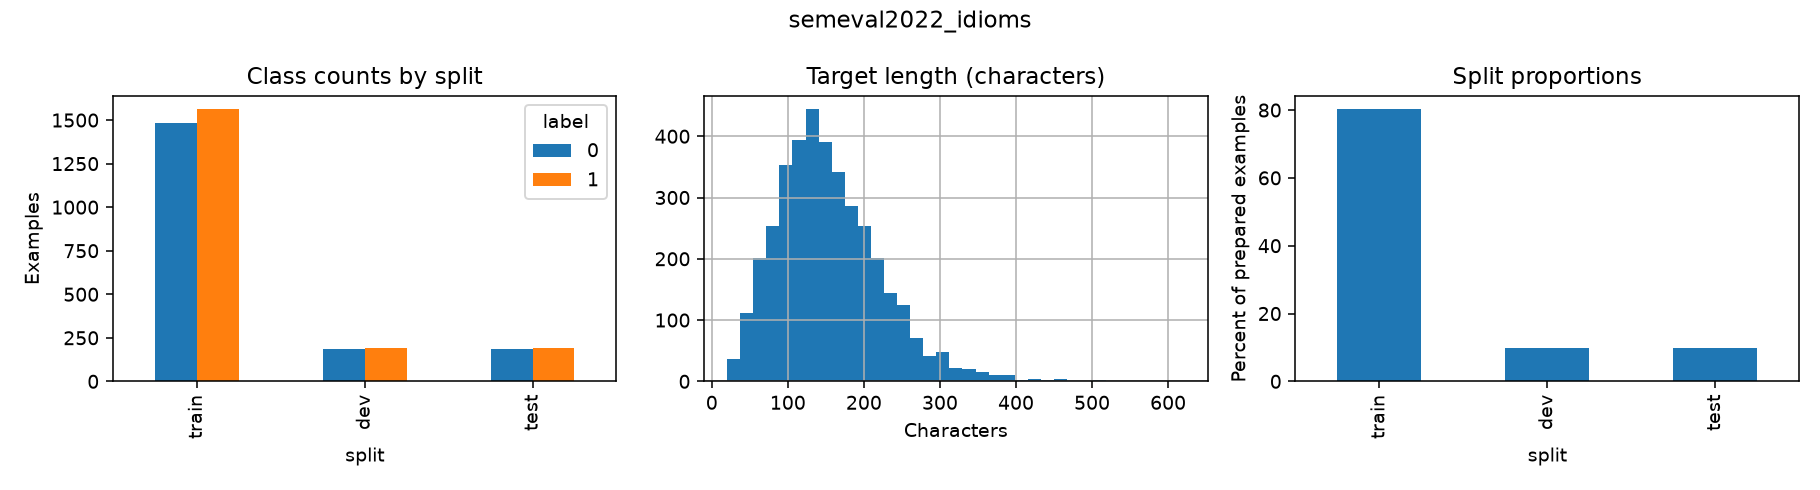

In [2]:
names = ['semeval2022_idioms']
for name in names:
    audit = explore(name)
    print(name)
    print(json.dumps({k:v for k,v in audit.items() if k != 'splits'}, indent=2))
    display(pd.DataFrame(audit['splits']).T)
    display(Image(filename=str(root / 'results' / 'figures' / (name.replace('/', '_') + '.png'))))

## Interpretation

Positive means humorous for HaHackathon, or idiomatic use of the specified MWE for the idiom dataset. These tasks can overlap with sarcasm and with each other. Never treat their negative labels as non-sarcastic gold.

HaHackathon preserves official dev/test roles. Idiom train/dev/test are new local MWE-disjoint splits; official test gold is unavailable. Context contains the preceding sentence; following_context is separate. MWE is a legitimate task input; source_label, ratings and human annotations are excluded from predictors.
